Structure of the first customer:
id: int
name: str
username: str
email: str
address: dict
    street: str
    suite: str
    city: str
    zipcode: str
    geo: dict
        lat: str
        lng: str
phone: str
website: str
company: dict
    name: str
    catchPhrase: str
    bs: str

DataFrame shape: (10, 12)
customer_id       int64
name             object
username         object
email            object
email_domain     object
phone            object
city             object
zipcode          object
latitude        float64
longitude       float64
company          object
website          object
dtype: object
pandas agrees with hand-written city counts: True


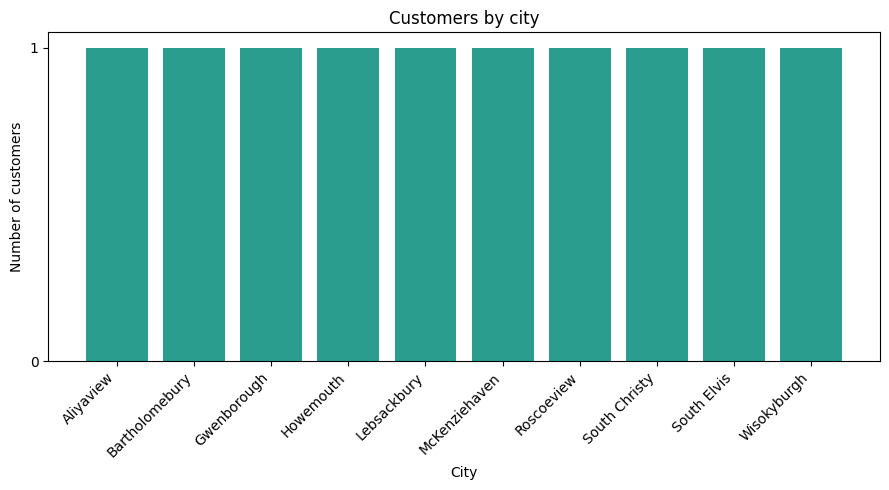

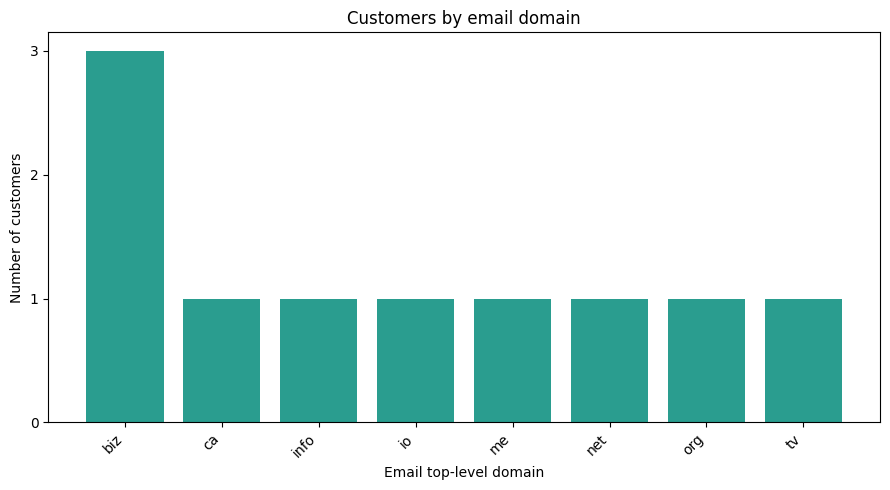


Customers retrieved : 10
Unique cities       : 10
Most common city    : Aliyaview (1)
Email domains       : {'biz': 3, 'ca': 1, 'info': 1, 'io': 1, 'me': 1, 'net': 1, 'org': 1, 'tv': 1}
Chart saved to      : output/customer_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
"""
Day 1 - API Data Analysis Using Python Structures
Squad Python Specialization - Data Science, AI & Analytics
"""
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

API_URL = "https://jsonplaceholder.typicode.com/users"
OUTPUT_DIR = Path("output")


def get_customers(url: str = API_URL) -> list[dict]:
    """Fetch the customer list. Report failures clearly instead of crashing."""
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        return response.json()
    except requests.exceptions.RequestException as e:
        print(f"Could not fetch customer data: {e}")
    except ValueError:
        print("The API response was not valid JSON.")
    return []


def explore(record: dict, indent: int = 0) -> None:
    """Print every key in a (possibly nested) record with its type, indented by depth."""
    spaces = "    " * indent
    if isinstance(record, dict):
        for key, value in record.items():
            print(f"{spaces}{key}: {type(value).__name__}")
            if isinstance(value, (dict, list)):
                explore(value, indent + 1)
    elif isinstance(record, list):
        for i, item in enumerate(record):
            print(f"{spaces}[{i}]: {type(item).__name__}")
            if isinstance(item, (dict, list)):
                explore(item, indent + 1)


def extract_attributes(customers: list[dict]) -> list[dict]:
    """Return one flat dict per customer with the attributes listed in the task."""
    rows = []
    for c in customers:
        rows.append({
            "customer_id": c["id"],
            "name": c["name"],
            "username": c["username"],
            "email": c["email"],
            "email_domain": c["email"].split("@")[1].split(".")[-1],  # tld, e.g. 'biz'
            "phone": c["phone"],
            "city": c["address"]["city"],
            "zipcode": c["address"]["zipcode"],
            "latitude": float(c["address"]["geo"]["lat"]),
            "longitude": float(c["address"]["geo"]["lng"]),
            "company": c["company"]["name"],
            "website": c["website"],
        })
    return rows


def unique_cities(customers: list[dict]) -> set[str]:
    """Return the set of distinct cities."""
    return {c["address"]["city"] for c in customers}


def city_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per city using a plain loop (no Counter, no pandas)."""
    counts = {}
    for c in customers:
        city = c["address"]["city"]
        counts[city] = counts.get(city, 0) + 1
    return counts


def email_domain_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per email top-level domain using a dict comprehension."""
    tlds = [c["email"].split("@")[1].split(".")[-1] for c in customers]
    return {t: tlds.count(t) for t in set(tlds)}


def to_dataframe(rows: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(rows)


def sort_counts(counts: dict[str, int]) -> list[tuple]:
    """Most common first, ties broken alphabetically."""
    return sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))


def plot_distribution(counts: dict[str, int], path: Path,
                      title: str = "Customers by city", xlabel: str = "City") -> None:
    """Save a labelled chart of the distribution to path."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    items = sort_counts(counts)
    labels = [k for k, _ in items]
    values = [v for _, v in items]

    plt.figure(figsize=(9, 5))
    plt.bar(labels, values, color="#2a9d8f")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Number of customers")
    plt.yticks(range(0, max(values) + 1))
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()
    plt.close()


if __name__ == "__main__":
    customers = get_customers(API_URL)
    if not customers:
        raise SystemExit("No data retrieved, stopping.")

    # Task 2: structure
    print("Structure of the first customer:")
    explore(customers[0])

    # Tasks 3-5: plain Python
    rows = extract_attributes(customers)
    cities = unique_cities(customers)
    by_city = city_counts(customers)
    by_domain = email_domain_counts(customers)
    top_city, top_n = sort_counts(by_city)[0]

    # Task 6: pandas
    df = to_dataframe(rows)
    print("\nDataFrame shape:", df.shape)
    print(df.dtypes)
    pandas_counts = df["city"].value_counts().to_dict()
    print("pandas agrees with hand-written city counts:", pandas_counts == by_city)

    # Task 7: CSVs
    OUTPUT_DIR.mkdir(exist_ok=True)
    df.to_csv(OUTPUT_DIR / "customers.csv", index=False)
    city_df = pd.DataFrame(sort_counts(by_city), columns=["city", "customer_count"])
    city_df.to_csv(OUTPUT_DIR / "city_counts.csv", index=False)

    # Task 8: charts
    chart_path = OUTPUT_DIR / "customer_distribution.png"
    plot_distribution(by_city, chart_path, "Customers by city", "City")
    plot_distribution(by_domain, OUTPUT_DIR / "email_domain_distribution.png",
                      "Customers by email domain", "Email top-level domain")

    # Console findings (expected_output.md format)
    print("\nCustomers retrieved :", len(customers))
    print("Unique cities       :", len(cities))
    print(f"Most common city    : {top_city} ({top_n})")
    print("Email domains       :", dict(sort_counts(by_domain)))
    print("Chart saved to      :", chart_path)

    # Colab only: download the output folder as a zip
    try:
        from google.colab import files
        shutil.make_archive("output", "zip", "output")
        files.download("output.zip")
    except ImportError:
        pass
